In [19]:
import numpy as np
from scipy.fft import fft2, ifft2

def fourier_filter(field, width, filterscale, kernel):
    """
    Filters a given field based on the specified mode and kernel.

    Parameters:
    - field: the field to base the filter on
    - width: controls the filter's boundary steepness
    - filterscale: determines the filtering scale
    - kernel: "tanh", "gaussian", "heaviside", etc.
    
    Returns:
    - filtered_field: the filtered field
    """
    # Generate the grid

    hey = np.linspace(0,Nx//2,(Nx//2)+1)
    hey2 = np.linspace(-((Nx//2)-1),-1,((Nx//2)-1))
    q = np.concatenate((hey,hey2))

    X = np.outer(q, np.ones_like(q))
    Y = np.outer(np.ones_like(q), q)
    R = np.sqrt(X**2 + Y**2)
    
    # Create the filter kernel
    if kernel == "tanh":
        G = -0.5 * (np.tanh(width * (R - filterscale)) - 1)
    elif kernel == "gaussian":
        G = np.exp(-((R - filterscale) ** 2) / (2 * width**2))
    elif kernel == "Itanh":
        G = -0.5 * (-np.tanh(width * (R - filterscale)) - 1)
    elif kernel == "Igaussian":
        G = 1 - np.exp(-((R - filterscale) ** 2) / (2 * width**2))
    elif kernel == "symheaviside":
        G = (np.abs(R) <= filterscale).astype(float)
    elif kernel == "Isymheaviside":
        G = (np.abs(R) >= filterscale).astype(float)
    elif kernel == "symtanh":
        G = -0.5 * (np.tanh(width * (R - filterscale)) + 1) - 0.5 * (np.tanh(-width * (R + filterscale)) - 1)
    elif kernel == "Isymtanh":
        G = -0.5 * (-np.tanh(width * (R - filterscale)) - 1) - 0.5 * (-np.tanh(-width * (R + filterscale)) - 1)
    elif kernel == "boxheaviside":
        n = Nx
        k = np.arange(n)
        k[k > n/2] = k[k > n/2] - n
    
        mask = np.abs(k) < filterscale
        G = np.outer(mask, mask)
    else:
        raise ValueError('ERROR: valid kernels are "tanh", "gaussian", "heaviside", etc.')

    # Apply the filter based on the mode
    filtered_field = np.zeros_like(field)
    if field.ndim == 4:  # Tensor field
        for i in range(field.shape[3]): # iterates over tensor components
            for j in range(field.shape[2]): # iterates over time
                fourier_field = np.fft.fft2(field[:, :, j, i])
                filtered_fourier_field = fourier_field * G
                filtered_field[:, :, j, i] = np.real(np.fft.ifft2(filtered_fourier_field))
    elif field.ndim == 3:  # Single 3D field
        for i in range(field.shape[2]):
            fourier_field = np.fft.fft2(field[:, :, i])
            filtered_fourier_field = fourier_field * G
            filtered_field[:, :, i] = np.real(np.fft.ifft2(filtered_fourier_field))
    else:
        raise ValueError('ERROR: field must have right dimensions')

    return filtered_field


def curl(U, V, dx, dy): # curl of vector fields
    nx, ny, nt = U.shape
    kx = np.fft.fftfreq(nx, d=dx) * 2 * np.pi
    ky = np.fft.rfftfreq(ny, d=dy) * 2 * np.pi
    kx, ky = np.meshgrid(kx, ky, indexing='ij')
    output = np.zeros((nx, ny, nt))
    for t in range(nt):
        u_FT = np.fft.rfftn(U[:, :, t])
        v_FT = np.fft.rfftn(V[:, :, t])
        i = 1j
        dyu = np.fft.irfftn(i * ky * u_FT, s=(nx, ny))
        dxv = np.fft.irfftn(i * kx * v_FT, s=(nx, ny))
        rhs = dxv - dyu
        rhs_FT = np.fft.rfftn(rhs)
        curl = np.fft.irfftn(rhs_FT, s=(nx, ny))
        output[:, :, t] = curl
    return output


def DX(U, V, dx, dy): # derivative of vector fields
    nx, ny, nt = U.shape
    kx = np.fft.fftfreq(nx, d=dx) * 2 * np.pi
    ky = np.fft.rfftfreq(ny, d=dy) * 2 * np.pi
    kx, ky = np.meshgrid(kx, ky, indexing='ij')
    output = np.zeros((nx, ny, nt, 2))
    for t in range(nt):
        u_FT = np.fft.rfftn(U[:, :, t])
        v_FT = np.fft.rfftn(V[:, :, t])
        i = 1j
        dxu = np.fft.irfftn(i * kx * u_FT, s=(nx, ny))
        dxv = np.fft.irfftn(i * kx * v_FT, s=(nx, ny)) 
        rhs_FT = np.fft.rfftn(dxu)
        rhs2_FT = np.fft.rfftn(dxv)
        output[:, :, t, 0] = np.fft.irfftn(rhs_FT, s=(nx, ny))
        output[:, :, t, 1] = np.fft.irfftn(rhs2_FT, s=(nx, ny))
    return output

def DY(U, V, dx, dy): # derivative of vector fields
    nx, ny, nt = U.shape
    kx = np.fft.fftfreq(nx, d=dx) * 2 * np.pi
    ky = np.fft.rfftfreq(ny, d=dy) * 2 * np.pi
    kx, ky = np.meshgrid(kx, ky, indexing='ij')
    output = np.zeros((nx, ny, nt, 2))
    for t in range(nt):
        u_FT = np.fft.rfftn(U[:, :, t])
        v_FT = np.fft.rfftn(V[:, :, t])
        i = 1j
        dyu = np.fft.irfftn(i * ky * u_FT, s=(nx, ny))
        dyv = np.fft.irfftn(i * ky * v_FT, s=(nx, ny)) 
        rhs_FT = np.fft.rfftn(dyu)
        rhs2_FT = np.fft.rfftn(dyv)
        output[:, :, t, 0] = np.fft.irfftn(rhs_FT, s=(nx, ny))
        output[:, :, t, 1] = np.fft.irfftn(rhs2_FT, s=(nx, ny))
    return output

In [21]:
from commons.identify_models import *
import copy
import h5py
import numpy as np
from utils import save, load
from library import *
from continuous.process_library_terms import *
import gc
from commons.identify_models import *
import copy
import jax
import jax.numpy as jnp
from jax_cfd.base import boundaries, grids, pressure, finite_differences as fd
import jax_cfd.base as cfd
import jax_cfd.base.grids as grids
import jax_cfd.spectral as spectral
import numpy as np
import xarray 
import xarray as xr
import dataclasses
import time
from commons.utils import *
from commons.identify_models import *
import copy
jax.config.update("jax_enable_x64", True)

In [23]:
size = 1024
density = 1.
viscosity = 1e-5
#viscosity = 0
seed = 10
inner_steps = 10
outer_steps = 100

max_velocity = 2.0
cfl_safety_factor = 0.05
Lx =  2*jnp.pi
Ly = Lx
# Define the physical dimensions of the simulation.
grid = cfd.grids.Grid((size, size), domain=((0, Lx), (0, Ly)))
Nx = Ny = size
dy = Lx/size
dx = Ly/size

grid = grids.Grid((size, size), domain=((0, 2 * jnp.pi), (0, 2 * jnp.pi)))
#dt = cfd.equations.stable_time_step(max_velocity, cfl_safety_factor, viscosity, grid)
Lt = 0.5
dt = Lt/inner_steps/outer_steps
# Define the step function with Kolmogorov forcing
smooth = True
step_fn = spectral.time_stepping.crank_nicolson_rk4(
    spectral.equations.NavierStokes2D(viscosity, grid, smooth=smooth), dt)

# Create the trajectory function
trajectory_fn = cfd.funcutils.trajectory(
    cfd.funcutils.repeated(step_fn, inner_steps), outer_steps)

# Initial velocity field and FFT of vorticity
v0 = cfd.initial_conditions.filtered_velocity_field(jax.random.PRNGKey(42), grid, max_velocity, 4)
vorticity0 = cfd.finite_differences.curl_2d(v0).data
vorticity_hat0 = jnp.fft.rfftn(vorticity0)

# Run the simulation to get the trajectory of vorticity in spectral space
_, trajectory_hat = trajectory_fn(vorticity_hat0)

# Transform vorticity back to real space for each time step
vorticity_trajectory = jnp.fft.irfftn(trajectory_hat, axes=(1, 2))

Nt = outer_steps


In [24]:

u_trajectory = []
v_trajectory = []

velocity_solve = spectral.utils.vorticity_to_velocity(grid)

# Loop over each time step in the vorticity trajectory
for vorticity in vorticity_trajectory:
    # Transform vorticity to Fourier domain
    vorticity_hat = jnp.fft.rfftn(vorticity, axes=(0, 1))

    # Use velocity_solve to compute velocity components in Fourier domain
    uhat, vhat = velocity_solve(vorticity_hat)

    # Transform velocity components back to real space
    u_real = jnp.fft.irfftn(uhat, axes=(0, 1))
    v_real = jnp.fft.irfftn(vhat, axes=(0, 1))

    # Append the real-space velocity components to the trajectory lists
    u_trajectory.append(u_real)
    v_trajectory.append(v_real)

# Convert velocity trajectories to arrays for easier manipulation
u_trajectory = jnp.stack(u_trajectory)
v_trajectory = jnp.stack(v_trajectory)
# Create spatial coordinates
spatial_coord = jnp.linspace(0, 2 * jnp.pi, size, endpoint=False)  # Same for x and y
coords = {
    'time': dt * jnp.arange(outer_steps) * inner_steps,
    'x': spatial_coord,
    'y': spatial_coord,
}

# Save the real-space velocity trajectory in an xarray Dataset
ds = xr.Dataset(
    {
        'u': (('time', 'x', 'y'), u_trajectory),
        'v': (('time', 'x', 'y'), v_trajectory),
    },
    coords=coords,
)
dt = dt*inner_steps
Lt = dt*outer_steps


In [26]:
V = ds['v'].values 
U = ds['u'].values
U = np.transpose(U, (1,2,0))
V = np.transpose(V, (1,2,0))
print(ds)
print(dt/inner_steps)
print(dt*viscosity/dx/dx)
u_has_nan = ds['u'].isnull().any().item()
v_has_nan = ds['v'].isnull().any().item()

print(f"Does 'u' contain NaN values? {u_has_nan}")
print(f"Does 'v' contain NaN values? {v_has_nan}")


<xarray.Dataset> Size: 2GB
Dimensions:  (time: 100, x: 1024, y: 1024)
Coordinates:
  * time     (time) float64 800B 0.0 0.005 0.01 0.015 ... 0.48 0.485 0.49 0.495
  * x        (x) float64 8kB 0.0 0.006136 0.01227 0.01841 ... 6.265 6.271 6.277
  * y        (y) float64 8kB 0.0 0.006136 0.01227 0.01841 ... 6.265 6.271 6.277
Data variables:
    u        (time, x, y) float64 839MB ...
    v        (time, x, y) float64 839MB ...
0.0005
0.0013280370182368498
Does 'u' contain NaN values? False
Does 'v' contain NaN values? False


In [27]:
def pressure_poisson(U, V, dx, dy, density=1.0):
    nx, ny, nt = U.shape
    kx = np.fft.fftfreq(nx, d=dx) * 2 * np.pi
    ky = np.fft.rfftfreq(ny, d=dy) * 2 * np.pi
    kx, ky = np.meshgrid(kx, ky, indexing='ij')
    k_squared = kx**2 + ky**2
    k_squared[0, 0] = np.inf 
    P = np.zeros((nx, ny, nt))
    for t in range(nt):
        u_FT = np.fft.rfftn(U[:, :, t])
        v_FT = np.fft.rfftn(V[:, :, t])
        i = 1j
        dxu = np.fft.irfftn(i * kx * u_FT, s=(nx, ny))
        dyu = np.fft.irfftn(i * ky * u_FT, s=(nx, ny))
        dxv = np.fft.irfftn(i * kx * v_FT, s=(nx, ny))
        dyv = np.fft.irfftn(i * ky * v_FT, s=(nx, ny))
        rhs = dxu**2 + 2 * dyu * dxv + dyv**2
        rhs_FT = np.fft.rfftn(rhs)
        pressure_FT = density * rhs_FT / k_squared
        pressure = np.fft.irfftn(pressure_FT, s=(nx, ny))
        P[:, :, t] = pressure
    return P

P = pressure_poisson(U, V, dx, dy)


print(f"V: Shape = {V.shape}, Type = {type(V)}")
print(f"U: Shape = {U.shape}, Type = {type(U)}")
print(f"P: Shape = {P.shape}, Type = {type(P)}")

V: Shape = (1024, 1024, 100), Type = <class 'numpy.ndarray'>
U: Shape = (1024, 1024, 100), Type = <class 'numpy.ndarray'>
P: Shape = (1024, 1024, 100), Type = <class 'numpy.ndarray'>


In [10]:
def test_filter (filterscale):
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    ## construct observables
    filterkernel = "boxheaviside"
    
    u = np.stack((U, V), axis=3) # indexed as x,y,t,vector_component
    u_bar = fourier_filter(u, 1, filterscale, filterkernel) # MAKE SURE DATA DEALIASED ON MASK WITH CORRESPONDING TO FILTER, ie, circular or rectangular
    p_bar = fourier_filter(P, 1, filterscale, filterkernel)
    u_prime = u - u_bar
    
    '''
    # dissipation rate
    dxu = DX(u_prime[:,:,:,0],u_prime[:,:,:,1],dx,dy)
    dyu = DY(u_prime[:,:,:,0],u_prime[:,:,:,1],dx,dy)
    epsilon = np.square(dxu[:,:,:,0]) + np.square(dxu[:,:,:,1]) + np.square(dyu[:,:,:,0]) + np.square(dyu[:,:,:,1])
    del dxu
    del dyu
    epsilon = fourier_filter(epsilon, 1, filterscale, filterkernel)
    
    # reynolds stresses
    R_xx = fourier_filter( np.multiply(u_prime[:,:,:,0],u_prime[:,:,:,0]) , 1, filterscale, filterkernel)
    R_xy = fourier_filter( np.multiply(u_prime[:,:,:,0],u_prime[:,:,:,1]) , 1, filterscale, filterkernel)
    R_yy = fourier_filter( np.multiply(u_prime[:,:,:,1],u_prime[:,:,:,1]) , 1, filterscale, filterkernel)
    del u_prime
    a1 = np.stack((R_xx, R_xy), axis=3) # indexed as x,y,t,vector_component
    a2 = np.stack((R_xy, R_yy), axis=3)
    del R_xx
    del R_xy
    del R_yy
    a = np.stack((a1, a2), axis=4)
    del a1
    del a2
    '''
    # exact closure
    corr_xx = fourier_filter( np.multiply(u[:,:,:,0],u[:,:,:,0]) , 1, filterscale, filterkernel)
    corr_xy = fourier_filter( np.multiply(u[:,:,:,0],u[:,:,:,1]) , 1, filterscale, filterkernel)
    corr_yy = fourier_filter( np.multiply(u[:,:,:,1],u[:,:,:,1]) , 1, filterscale, filterkernel)
    tau_xx = np.multiply(u_bar[:,:,:,0],u_bar[:,:,:,0]) - corr_xx # now here u is indexed as x,y,t instead of matlab's y,x,t
    tau_xy = np.multiply(u_bar[:,:,:,0],u_bar[:,:,:,1]) - corr_xy
    tau_yy = np.multiply(u_bar[:,:,:,1],u_bar[:,:,:,1]) - corr_yy
    del corr_xx
    del corr_xy
    del corr_yy
    #print(f"tau_xx: Shape = {tau_xx.shape}, Type = {type(tau_xx)}")
    #print(f"tau_xy: Shape = {tau_xy.shape}, Type = {type(tau_xy)}")
    #print(f"tau_yy: Shape = {tau_yy.shape}, Type = {type(tau_yy)}")
    b1 = np.stack((tau_xx, tau_xy), axis=3) # indexed as x,y,t,vector_component
    b2 = np.stack((tau_xy, tau_yy), axis=3)
    del tau_xx
    del tau_xy
    del tau_yy
    #print(b1.shape)
    #print(b2.shape)
    b = np.stack((b1, b2), axis=4)
    del b1
    del b2
    #print(b.shape)
    
    #endclosure
    beta=12
    u = np.stack((U, V), axis=3) # indexed as x,y,t,vector_component
    
    bobs = Observable(string='b', rank=2, can_commute_indices = True, antisymmetric = False)
    uobs = Observable(string='u', rank=1)
    pobs = Observable(string='p', rank=0)
    
    #robs = Observable(string='a', rank=2, can_commute_indices = True, antisymmetric = False)
    #epsilonobs = Observable(string='epsilon', rank=0)
    
    observables = [uobs, pobs, bobs] #, robs, epsilonobs]
    #observables = [uobs, pobs, bobs]
    data_dict = {'p': p_bar, 'u': u_bar, 'b': b} #, 'a': a, 'epsilon': epsilon}
    #data_dict = {'p': p_bar, 'u': u_bar, 'b': b}
    
    # create libraries
    np.random.seed(1)
    world_size = np.array(P.shape)
    pad = 0
    # fix random seed
    np.random.seed(1)
    dxs = [dx, dy, dt]
    # initial setup of dataset
    #corr_L = 5
    #corr_T = 5
    srd = SRDataset(world_size=world_size, data_dict=data_dict, observables=observables, dxs=dxs, 
                    irreps=SRDataset.all_rank2_irreps())
                    #irreps=(0, 1, 2))
    # initialize libraries, domains, and weights
    #srd.make_libraries(max_complexity=4, max_observables=3)
    srd.make_libraries(max_complexity=3)
    dom_width = 64
    dom_time = 50 #previously 20 (without interpolation)
    srd.make_domains(ndomains=150, domain_size=[dom_width, dom_width, dom_time], pad=pad)
    #srd.make_doma]ins(ndomains=10, domain_size=[dom_width, dom_width, dom_time], pad=pad)
    srd.make_weights(m=beta, qmax=0)
    srd.set_LT_scale(L=Lx*dom_width/Nx, T=Lt*dom_time/Nt) # note that this line must go before make_library_matrices
    srd.make_library_matrices(debug=False)
    
    libs = srd.libs
    
    reg_opts_list = []
    for irrep in srd.irreps:
        # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold
        scaler = Scaler(sub_inds=None, char_sizes=libs[irrep].col_weights, row_norms=None)
        #init = Initializer(method='combinatorial', start_k=2)
        #init = Initializer(method='combinatorial', start_k=9999)
        init = Initializer(method='power', start_k=10)
        #res = Residual(residual_type='fixed_column', anchor_col=0)
        res = Residual(residual_type='matrix_relative')
        
        iterator = ModelIterator(max_k=12, backward_forward=True, max_passes=10)
        thres = Threshold(threshold_type='jump', gamma=1.1, delta=1e-8, n_terms=None)
        #thres = Threshold(threshold_type='information', ic=AIC)
        #thres = Threshold(threshold_type='jump', gamma=1.5, n_terms=3)
        
        opts = {'scaler': scaler, 'initializer': init, 'residual': res,
                'model_iterator': iterator, 'threshold': thres}
        opts['verbose'] = False
        opts['inhomog'] = False
        opts['inhomog_col'] = None
        reg_opts_list.append(opts)
    
    eqs, lambdas, reg_results, derived_eqs, excluded_terms = interleave_identify([libs[i] for i in srd.irreps], 
    reg_opts_list, threshold=1e-5, experimental=True)
    #, max_equations=10)
    
    lib1 = srd.libs[srd.irreps[1]]
    for match in regex_find(lib1.terms, r'∂t u_α'):
        print(match)
    dtu = lib1.Q[:, match[0]]
    
    for match in regex_find(lib1.terms, r'u_β · ∂β u_α'):
        print(match)
    adv = lib1.Q[:, match[0]]
    
    for match in regex_find(lib1.terms, r'∂α p'):
        print(match)
    dp = lib1.Q[:, match[0]]
    
    for match in regex_find(lib1.terms, r'∂β² u_α'):
        print(match)
    viscosity = 1e-5*lib1.Q[:, match[0]]
    
    for match in regex_find(lib1.terms, r'∂β b_αβ'):
        print(match)
    stress_tensorz = lib1.Q[:, match[0]]
    
    print("With closure: ", np.linalg.norm(dtu+adv+dp-viscosity-stress_tensorz))
    print("Without closure: ", np.linalg.norm(dtu+adv+dp-viscosity))
    
    print(np.linalg.norm(dtu), np.linalg.norm(adv), np.linalg.norm(dp),np.linalg.norm(viscosity), np.linalg.norm(stress_tensorz))

    

In [12]:
for i in range(11):
    test_filter(2**i)

##############################WORKING WITH FILTERSCALE1##########################################
##############################WORKING WITH FILTERSCALE1##########################################
##############################WORKING WITH FILTERSCALE1##########################################
##############################WORKING WITH FILTERSCALE1##########################################
##############################WORKING WITH FILTERSCALE1##########################################
##############################WORKING WITH FILTERSCALE1##########################################
##############################WORKING WITH FILTERSCALE1##########################################
##############################WORKING WITH FILTERSCALE1##########################################
##############################WORKING WITH FILTERSCALE1##########################################
##############################WORKING WITH FILTERSCALE1##########################################
####################

In [46]:
def test_filter_noclosure (filterscale):
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    print("##############################WORKING WITH FILTERSCALE"+str(filterscale)+"##########################################")
    ## construct observables
    filterkernel = "boxheaviside"
    
    u = np.stack((U, V), axis=3) # indexed as x,y,t,vector_component
    u_bar = fourier_filter(u, 1, filterscale, filterkernel) # MAKE SURE DATA DEALIASED ON MASK WITH CORRESPONDING TO FILTER, ie, circular or rectangular
    p_bar = fourier_filter(P, 1, filterscale, filterkernel)
    u_prime = u - u_bar
    
    '''
    # dissipation rate
    dxu = DX(u_prime[:,:,:,0],u_prime[:,:,:,1],dx,dy)
    dyu = DY(u_prime[:,:,:,0],u_prime[:,:,:,1],dx,dy)
    epsilon = np.square(dxu[:,:,:,0]) + np.square(dxu[:,:,:,1]) + np.square(dyu[:,:,:,0]) + np.square(dyu[:,:,:,1])
    del dxu
    del dyu
    epsilon = fourier_filter(epsilon, 1, filterscale, filterkernel)
    
    # reynolds stresses
    R_xx = fourier_filter( np.multiply(u_prime[:,:,:,0],u_prime[:,:,:,0]) , 1, filterscale, filterkernel)
    R_xy = fourier_filter( np.multiply(u_prime[:,:,:,0],u_prime[:,:,:,1]) , 1, filterscale, filterkernel)
    R_yy = fourier_filter( np.multiply(u_prime[:,:,:,1],u_prime[:,:,:,1]) , 1, filterscale, filterkernel)
    del u_prime
    a1 = np.stack((R_xx, R_xy), axis=3) # indexed as x,y,t,vector_component
    a2 = np.stack((R_xy, R_yy), axis=3)
    del R_xx
    del R_xy
    del R_yy
    a = np.stack((a1, a2), axis=4)
    del a1
    del a2
    '''
    
    
    #endclosure
    beta=12
    u = np.stack((U, V), axis=3) # indexed as x,y,t,vector_component
    
    
    uobs = Observable(string='u', rank=1)
    pobs = Observable(string='p', rank=0)
    
    #robs = Observable(string='a', rank=2, can_commute_indices = True, antisymmetric = False)
    #epsilonobs = Observable(string='epsilon', rank=0)
    
    observables = [uobs, pobs] #, robs, epsilonobs]
    #observables = [uobs, pobs, bobs]
    data_dict = {'p': p_bar, 'u': u_bar} #, 'a': a, 'epsilon': epsilon}
    #data_dict = {'p': p_bar, 'u': u_bar, 'b': b}
    
    # create libraries
    np.random.seed(1)
    world_size = np.array(P.shape)
    pad = 0
    # fix random seed
    np.random.seed(1)
    dxs = [dx, dy, dt]
    # initial setup of dataset
    #corr_L = 5
    #corr_T = 5
    srd = SRDataset(world_size=world_size, data_dict=data_dict, observables=observables, dxs=dxs, 
                    irreps=SRDataset.all_rank2_irreps())
                    #irreps=(0, 1, 2))
    # initialize libraries, domains, and weights
    #srd.make_libraries(max_complexity=4, max_observables=3)
    srd.make_libraries(max_complexity=3)
    dom_width = 64
    dom_time = 50 #previously 20 (without interpolation)
    srd.make_domains(ndomains=150, domain_size=[dom_width, dom_width, dom_time], pad=pad)
    #srd.make_doma]ins(ndomains=10, domain_size=[dom_width, dom_width, dom_time], pad=pad)
    srd.make_weights(m=beta, qmax=0)
    srd.set_LT_scale(L=Lx*dom_width/Nx, T=Lt*dom_time/Nt) # note that this line must go before make_library_matrices
    srd.make_library_matrices(debug=False)
    
    libs = srd.libs
    
    reg_opts_list = []
    for irrep in srd.irreps:
        # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold
        # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold
        scaler = Scaler(sub_inds=None, char_sizes=libs[irrep].col_weights, row_norms=None)
        #init = Initializer(method='combinatorial', start_k=2)
        #init = Initializer(method='combinatorial', start_k=9999)
        init = Initializer(method='power', start_k=10)
        #res = Residual(residual_type='fixed_column', anchor_col=0)
        res = Residual(residual_type='matrix_relative')
        
        iterator = ModelIterator(max_k=12, backward_forward=True, max_passes=10)
        thres = Threshold(threshold_type='jump', gamma=1.1, delta=1e-8, n_terms=None) #gamma-delta matter a lot
        #thres = Threshold(threshold_type='information', ic=AIC)
        #thres = Threshold(threshold_type='jump', gamma=1.5, n_terms=3)
        
        opts = {'scaler': scaler, 'initializer': init, 'residual': res,
                'model_iterator': iterator, 'threshold': thres}
        opts['verbose'] = False
        opts['inhomog'] = False
        opts['inhomog_col'] = None
        reg_opts_list.append(opts)
    
    eqs, lambdas, reg_results, derived_eqs, excluded_terms = interleave_identify([libs[i] for i in srd.irreps], 
    reg_opts_list, threshold=1, experimental=True)
    #, max_equations=10)
    
    

    

In [ ]:
for i in range(11):
    test_filter_noclosure(2**(10-i))

##############################WORKING WITH FILTERSCALE1024##########################################
##############################WORKING WITH FILTERSCALE1024##########################################
##############################WORKING WITH FILTERSCALE1024##########################################
##############################WORKING WITH FILTERSCALE1024##########################################
##############################WORKING WITH FILTERSCALE1024##########################################
##############################WORKING WITH FILTERSCALE1024##########################################
##############################WORKING WITH FILTERSCALE1024##########################################
##############################WORKING WITH FILTERSCALE1024##########################################
##############################WORKING WITH FILTERSCALE1024##########################################
##############################WORKING WITH FILTERSCALE1024#################################

In [11]:
import matplotlib.pyplot as plt

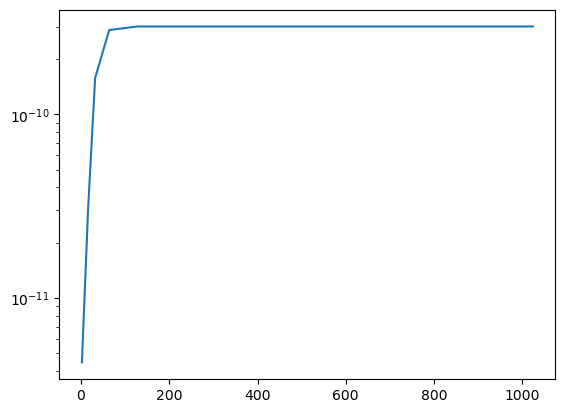

In [17]:
xdata = np.array([2,16,32,64,128,256,512,1024])
data = np.array([4.46e-12,3.05e-11,1.58e-10,2.88e-10,3.01e-10,3.01e-10,3.01e-10,3.01e-10])
plt.plot(xdata, data, label="Data set 1")
plt.yscale('log')
#plt.plot(x, y2, label="Data set 2")


